# GNSS Dataset Analysis

In [282]:
import numpy as np
import matplotlib, matplotlib.pyplot as plt
from utils import *
from solver_utils import *

In [283]:
raw_data, reference_data = load_satellite_data('satellite_data.npz')

In [284]:
time_grid = raw_data['time_grid'] - raw_data['time_grid'][0]

In [285]:
# Extract number of epochs
num_epochs = len(raw_data['time_grid'])

## Number of Available Satellites

In [286]:
num_sats = np.zeros(num_epochs)

for i in range(num_epochs):
   
    try:
        num_sats[i] = raw_data['sat_x'][i].shape[0]
    except:
        num_sats[i] = 1

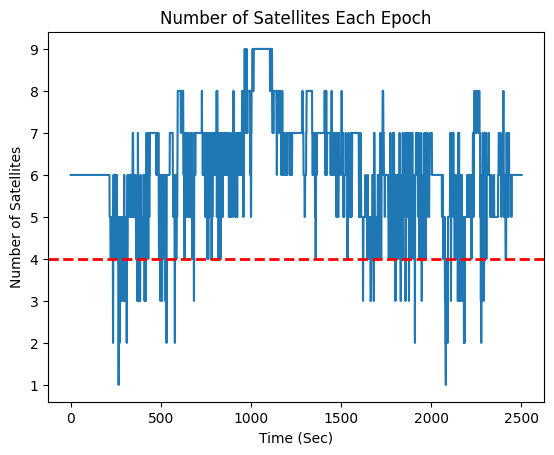

In [287]:
plt.plot(num_sats)
plt.xlabel('Time (Sec)')
plt.ylabel('Number of Satellites')
plt.title('Number of Satellites Each Epoch')
plt.axhline(y=4, color='r', linestyle='--', linewidth=2)

In [288]:
print(f"Number of epochs with insufficient number of satellites: {((np.sum(num_sats < 4) / num_epochs) * 100):.1f} % of trajectory")

Number of epochs with insufficient number of satellites: 3.0 % of trajectory


## Pseudorange STD

### Minimum

In [289]:
min_sv_std = np.zeros(num_epochs)

for i in range(num_epochs):
    min_sv_std[i] = np.min(raw_data['rho_std'][i])

Text(0.5, 1.0, 'Minimum Pseudorange std Each Epoch')

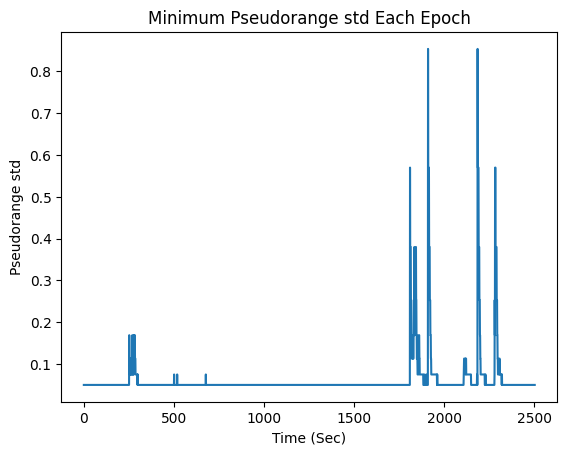

In [290]:
plt.plot(min_sv_std)
plt.xlabel('Time (Sec)')
plt.ylabel('Pseudorange std')
plt.title('Minimum Pseudorange std Each Epoch')

### Maximum

In [291]:
max_sv_std = np.zeros(num_epochs)

for i in range(num_epochs):
    max_sv_std[i] = np.max(raw_data['rho_std'][i])

Text(0.5, 1.0, 'Maximum Pseudorange std Each Epoch')

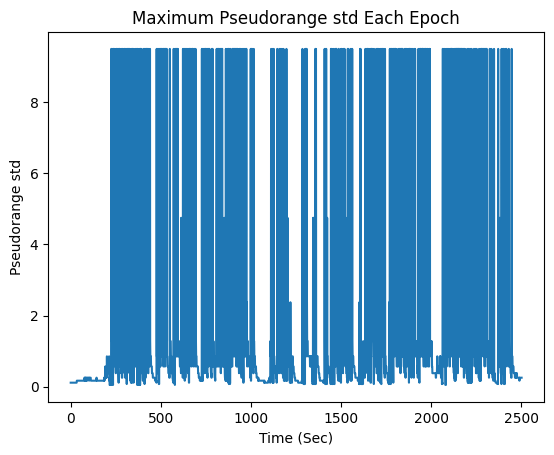

In [292]:
plt.plot(max_sv_std)
plt.xlabel('Time (Sec)')
plt.ylabel('Pseudorange std')
plt.title('Maximum Pseudorange std Each Epoch')

### Average

In [293]:
avg_sv_std = np.zeros(num_epochs)

for i in range(num_epochs):
    avg_sv_std[i] = np.mean(raw_data['rho_std'][i])

Text(0.5, 1.0, 'Average Pseudorange std Each Epoch')

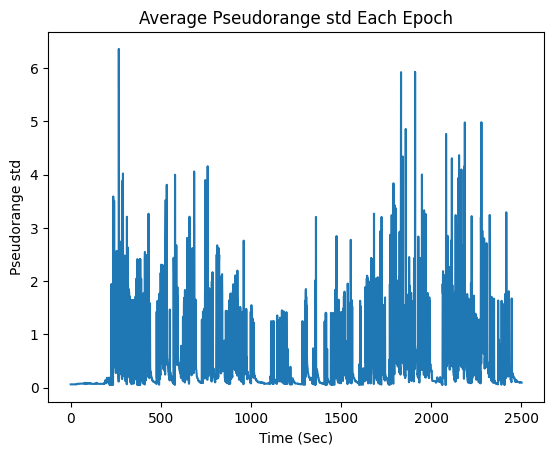

In [294]:
plt.plot(avg_sv_std)
plt.xlabel('Time (Sec)')
plt.ylabel('Pseudorange std')
plt.title('Average Pseudorange std Each Epoch')

## Satellite's Azimuth & Elevation

### Azimuth

In [295]:
az_values = np.concatenate([np.ravel(arr) for arr in raw_data['az_sat']])

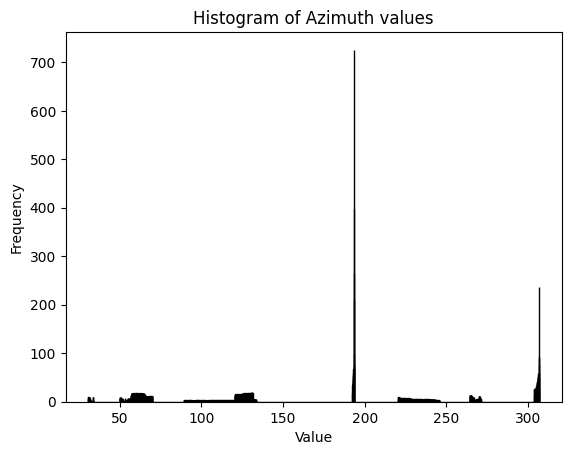

In [296]:
# Plot histogram
plt.hist(az_values, bins=5000, edgecolor='black')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Azimuth values')
plt.show()

In [297]:
# Calculate histogram
counts, bin_edges = np.histogram(az_values, bins=100)

# Find indices of the top two bins by count
top_two_indices = np.argsort(counts)[-2:][::-1]

for rank, idx in enumerate(top_two_indices, start=1):
    bin_start = bin_edges[idx]
    bin_end = bin_edges[idx+1]
    print(f"{rank} most frequent bin: {bin_start:.4f} to {bin_end:.4f} "
          f"with count {counts[idx]} which is {(counts[idx]/sum(num_sats))*100:.2f}% of the trajectory")

1 most frequent bin: 190.7782 to 193.5380 with count 2412 which is 15.93% of the trajectory
2 most frequent bin: 303.9297 to 306.6895 with count 1961 which is 12.95% of the trajectory


### Elevation

In [298]:
ele_values = np.concatenate([np.ravel(arr) for arr in raw_data['el_sat']])

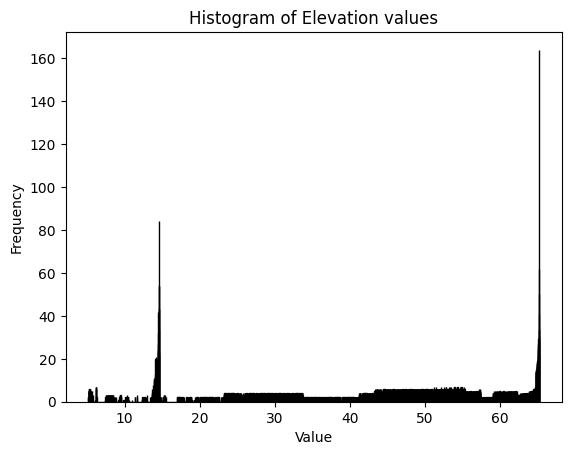

In [299]:
# Plot histogram
plt.hist(ele_values, bins=5000, edgecolor='black')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Histogram of Elevation values')
plt.show()

In [300]:
# Calculate histogram
counts, bin_edges = np.histogram(ele_values, bins=100)

# Find indices of the top two bins by count
top_two_indices = np.argsort(counts)[-2:][::-1]

for rank, idx in enumerate(top_two_indices, start=1):
    bin_start = bin_edges[idx]
    bin_end = bin_edges[idx+1]
    print(f"{rank} most frequent bin: {bin_start:.4f} to {bin_end:.4f} "
          f"with count {counts[idx]} which is {(counts[idx]/sum(num_sats))*100:.2f}% of the trajectory")

1 most frequent bin: 64.6233 to 65.2240 with count 1083 which is 7.15% of the trajectory
2 most frequent bin: 14.1607 to 14.7614 with count 828 which is 5.47% of the trajectory


## STD of Reference Trajectory

### Latitude

Text(0, 0.5, 'std value')

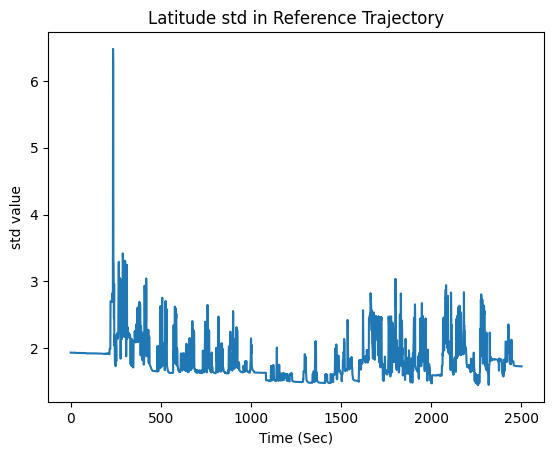

In [301]:
plt.plot(reference_data['ref_lat_std'])
plt.title('Latitude std in Reference Trajectory')
plt.xlabel('Time (Sec)')
plt.ylabel('std value')

### Longitude

Text(0, 0.5, 'std value')

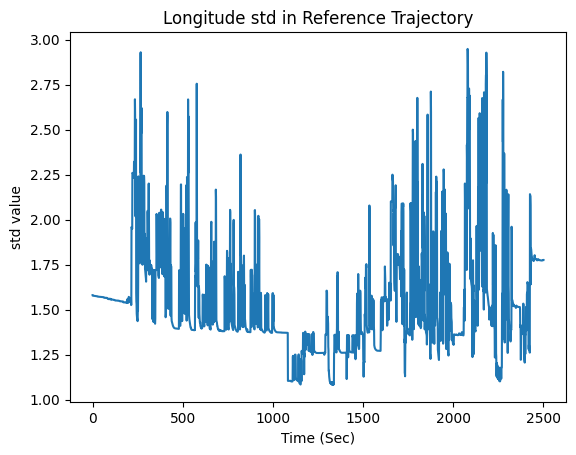

In [302]:
plt.plot(reference_data['ref_long_std'])
plt.title('Longitude std in Reference Trajectory')
plt.xlabel('Time (Sec)')
plt.ylabel('std value')

### Altitude

Text(0, 0.5, 'std value')

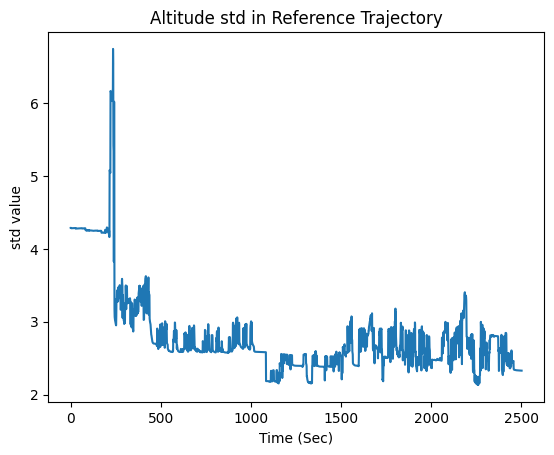

In [303]:
plt.plot(reference_data['ref_alt_std'])
plt.title('Altitude std in Reference Trajectory')
plt.xlabel('Time (Sec)')
plt.ylabel('std value')

## Dilution of Precision

In [304]:
G = []
COND = []
DOP = []

for i in range(num_epochs):

    # extract receiver position
    phi_rec = reference_data['ref_lat'][i]
    lam_rec = reference_data['ref_long'][i]
    h_rec = reference_data['ref_alt'][i]

    # convert to ECEF
    x_rec, y_rec, z_rec = geodetic_to_ecef(phi_rec, lam_rec, h_rec)
    pos_rec = np.array([x_rec, y_rec, z_rec]).reshape(1,-1)

    # extract satellite position
    try:
        x_sat = raw_data['sat_x'][i].reshape(-1, 1)
        y_sat = raw_data['sat_y'][i].reshape(-1, 1)
        z_sat = raw_data['sat_z'][i].reshape(-1, 1)
    except:
        x_sat = raw_data['sat_x'][i]
        y_sat = raw_data['sat_y'][i]
        z_sat = raw_data['sat_z'][i]

    pos_sat = np.hstack([x_sat, y_sat, z_sat])

    # compute los vectors
    los_vecs = compute_los_unit_vectors(pos_sat, pos_rec)

    # compute G matrix
    g_u, _ = compute_geometry_matrix(los_vecs)

    g = g_u[:, 0:4]

    G.append(g)

    # compute DOP
    DOP.append(compute_dop_xyz(g_u))

    # compute COND
    COND.append(np.linalg.cond(g.T @ g))

### Condition Number of (G.T G)

Text(0, 0.5, 'Condition Number')

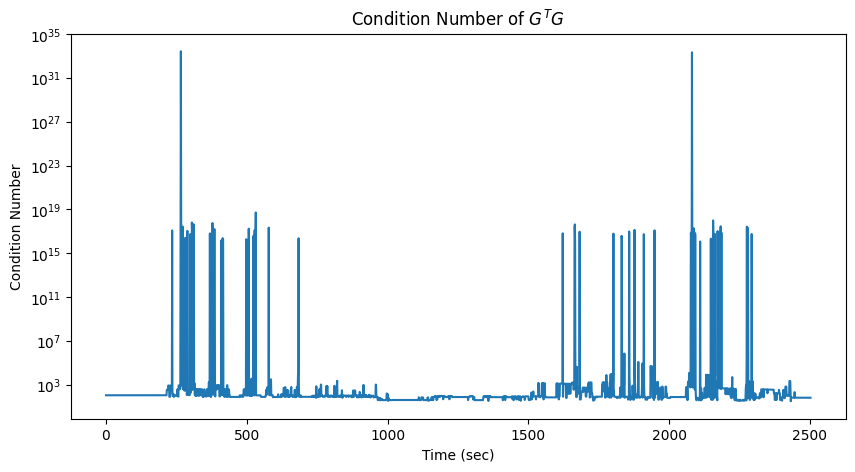

In [305]:
fig = plt.subplots(figsize=(10, 5))
plt.semilogy(np.asarray(COND))
plt.title(r'Condition Number of $G^TG$')
plt.xlabel('Time (sec)')
plt.ylabel('Condition Number')

### DOP_x,y,z (ECEF) & PDOP

In [306]:
x_DOP = np.zeros(num_epochs)
y_DOP = np.zeros(num_epochs)
z_DOP = np.zeros(num_epochs)
PDOP  = np.zeros(num_epochs)

for i in range(num_epochs):

    x_DOP[i] = DOP[i]['DOP_x']
    y_DOP[i] = DOP[i]['DOP_y']
    z_DOP[i] = DOP[i]['DOP_z']
    PDOP[i]  = DOP[i]['PDOP']

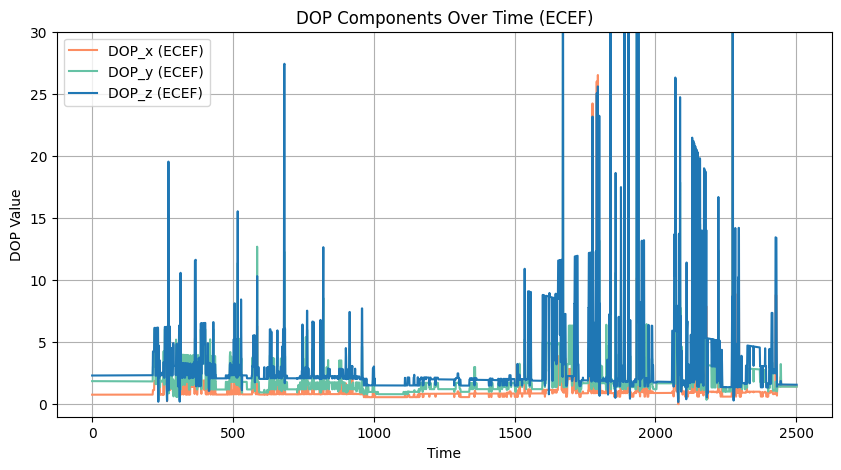

In [307]:
fig = plt.subplots(figsize=(10, 5))
# Plot DOP_x, DOP_y, and DOP_z over time
plt.plot(x_DOP, label="DOP_x (ECEF)", linestyle='-', color='#fc8d62')  # Orange
plt.plot(y_DOP, label="DOP_y (ECEF)", linestyle='-', color='#66c2a5')  # Teal
plt.plot(z_DOP, label="DOP_z (ECEF)", linestyle='-', color='#1f77b4')  # Blue
#plt.plot(time_grid, DOP_kf[3, :], label="PDOP", linestyle='-', color='#9467bd')  # Purple

# Labels and title
plt.xlabel("Time")
plt.ylabel("DOP Value")
plt.title("DOP Components Over Time (ECEF)")

# Legend
plt.legend()

plt.ylim(-1,30)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

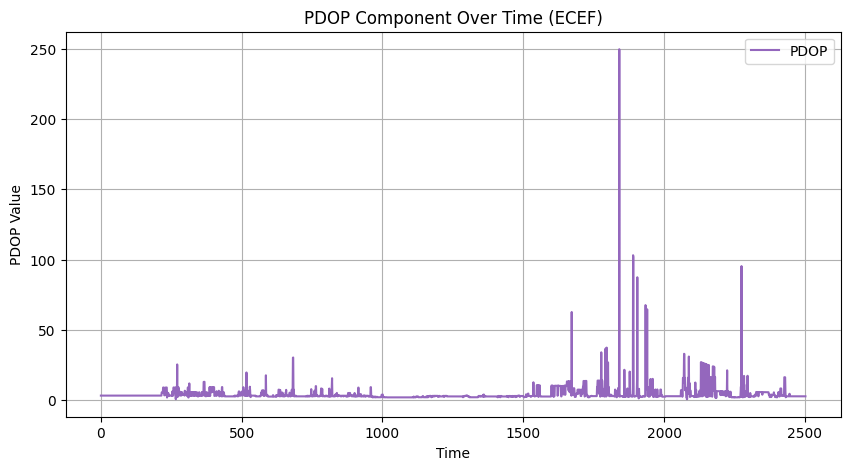

In [308]:
fig = plt.subplots(figsize=(10, 5))
plt.plot(time_grid, PDOP, label="PDOP", linestyle='-', color='#9467bd')  # Purple

# Labels and title
plt.xlabel("Time")
plt.ylabel("PDOP Value")
plt.title("PDOP Component Over Time (ECEF)")

# Legend
plt.legend()

#plt.ylim(-1,30)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

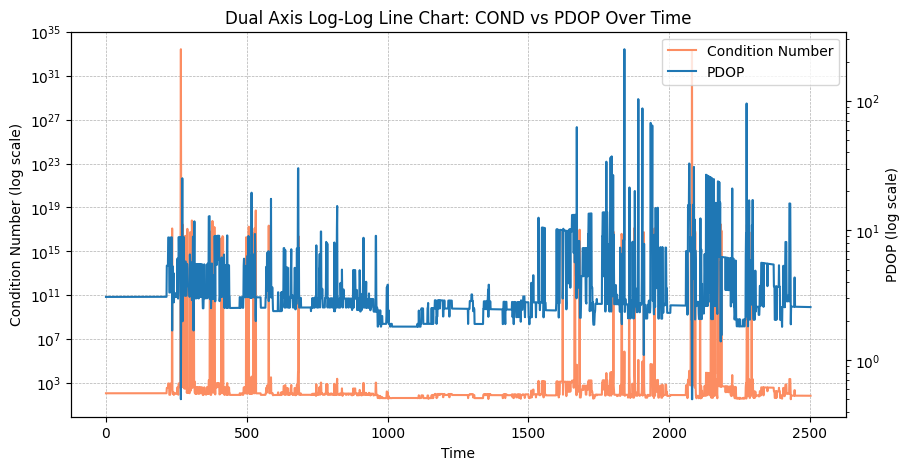

In [309]:
# Create the figure and axis
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot COND on primary y-axis (log scale)
line1, = ax1.plot(np.asarray(COND), '#fc8d62', label='Condition Number')
ax1.set_xlabel('Time')
ax1.set_ylabel('Condition Number (log scale)', color='black')
ax1.set_yscale('log')  # Logarithmic scale for COND
ax1.tick_params(axis='y', labelcolor='black')

# Create a secondary y-axis (log scale)
ax2 = ax1.twinx()
line2, = ax2.plot(PDOP, '#1f77b4', label='PDOP')
ax2.set_ylabel('PDOP (log scale)', color='black')
ax2.set_yscale('log')  # Logarithmic scale for PDOP
ax2.tick_params(axis='y', labelcolor='black')

# Title and grid
plt.title('Dual Axis Log-Log Line Chart: COND vs PDOP Over Time')
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Combine legends
lines = [line1, line2]
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc='upper right')

# Save as PDF (optional)
#plt.savefig("COND_DOP.pdf", format="pdf")

# Show plot
plt.show()

### HDOP & VDOP

In [310]:
def compute_R_le(phi, lam):

    R_el = np.array([
        [-np.sin(lam),           -np.sin(phi)*np.cos(lam),  np.cos(phi)*np.cos(lam)],
        [ np.cos(lam),           -np.sin(phi)*np.sin(lam),  np.cos(phi)*np.sin(lam)],
        [ 0.0,                    np.cos(phi),              np.sin(phi)]
    ])
    return R_el.T

In [311]:
def embed_rotation_matrix(R):
    
    R_tilde = np.zeros((4, 4))
    R_tilde[:3, :3] = R
    R_tilde[3, 3] = 1.0
    return R_tilde

In [312]:
EDOP = np.zeros(num_epochs)
NDOP = np.zeros(num_epochs)
HDOP = np.zeros(num_epochs)
VDOP = np.zeros(num_epochs)

for i in range(num_epochs):

    # extract lat long
    lat = reference_data['ref_lat'][i]
    long = reference_data['ref_long'][i]

    # compute and embed transformation matrix
    R_le = compute_R_le(lat, long)
    R_le_tilde = embed_rotation_matrix(R_le)

    # compute transformed geometry matrix
    g_tilde = G[i] @ R_le_tilde.T

    # compute DOP and store
    H = np.linalg.pinv(g_tilde.T @ g_tilde)

    EDOP[i] = np.sqrt(H[0,0])
    NDOP[i] = np.sqrt(H[1,1])
    VDOP[i] = np.sqrt(H[2,2])
    HDOP[i] = np.sqrt(H[0,0] + H[1,1])

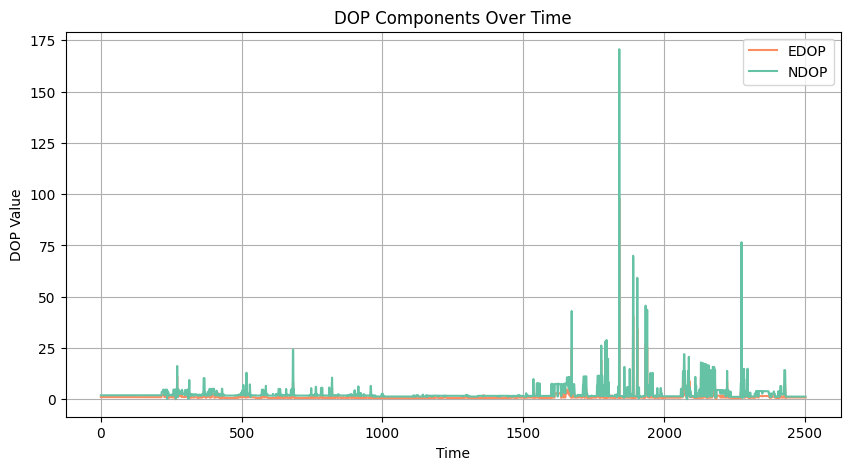

In [313]:
fig = plt.subplots(figsize=(10, 5))

plt.plot(EDOP, label="EDOP", linestyle='-', color='#fc8d62')  # Orange
plt.plot(NDOP, label="NDOP", linestyle='-', color='#66c2a5')  # Teal

# Labels and title
plt.xlabel("Time")
plt.ylabel("DOP Value")
plt.title("DOP Components Over Time")

# Legend
plt.legend()

#plt.ylim(-1,30)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

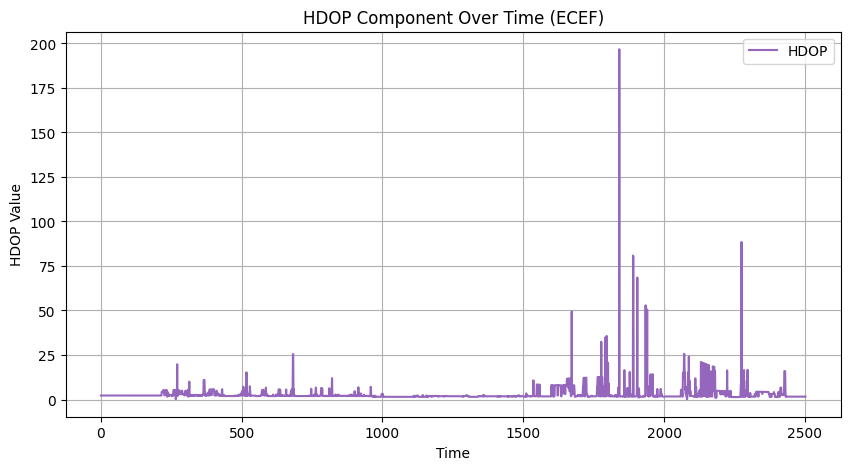

In [314]:
fig = plt.subplots(figsize=(10, 5))
plt.plot(HDOP, label="HDOP", linestyle='-', color='#9467bd')  # Purple

# Labels and title
plt.xlabel("Time")
plt.ylabel("HDOP Value")
plt.title("HDOP Component Over Time (ECEF)")

# Legend
plt.legend()

#plt.ylim(-1,30)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

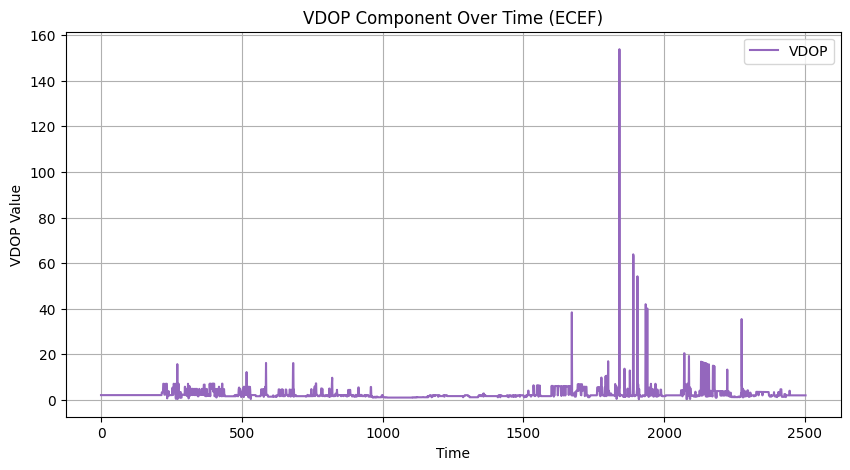

In [315]:
fig = plt.subplots(figsize=(10, 5))
plt.plot(VDOP, label="VDOP", linestyle='-', color='#9467bd')  # Purple

# Labels and title
plt.xlabel("Time")
plt.ylabel("VDOP Value")
plt.title("VDOP Component Over Time (ECEF)")

# Legend
plt.legend()

#plt.ylim(-1,30)

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()